# 1 · From probability models to generative AI

**Complete lesson · Python from the beginning · A statistician's perspective**

[Download the executed notebook](https://chikuang.github.io/teaching/genai/notebooks/01-probability-to-genai.ipynb) · [Set up Python](https://chikuang.github.io/teaching/genai/python-workflow.html)

You already know how to define a model, estimate its parameters, assess its fit, and simulate from it. These are useful starting points for generative AI. The unfamiliar part is often the data representation and software vocabulary, rather than the basic idea of learning a distribution.

By the end of this chapter you will fit a categorical distribution, generate observations from it, and build a small language model that generates short sequences. You will also understand why a model can assign high probability to a plausible sentence without establishing that the sentence is true.

The examples use a laptop CPU, NumPy, and Matplotlib. No GPU, pretrained model, API key, or prior Python knowledge is required. Run code cells **from top to bottom**: later cells use objects defined earlier. The website displays the outputs from a successful clean execution. To change a cell and run it yourself, use the downloadable notebook in JupyterLab or VS Code.

## 1.1 · What is a generative model?

Let $X$ be an observation and $P_0$ its unknown data-generating distribution. A statistical model specifies a family $\{P_\theta:\theta\in\Theta\}$. After observing training data $D$, we obtain an estimate $\widehat\theta$ or a posterior distribution for $\theta$.

There are several different things we might do next:

| Operation | Statistical question | Example |
|:--|:--|:--|
| Estimation | What parameter or function of the distribution is supported by the data? | Estimate a categorical probability vector. |
| Prediction | What distribution should we assign to an unobserved outcome? | Predict the next word given the preceding words. |
| Generation | How can we produce a new realization from the fitted distribution? | Draw a word from that categorical distribution. |
| Evaluation | How well does the fitted system perform on a specified population of tasks? | Measure held-out log loss on new sentences. |

For example, fitting a normal distribution and calling a random-number generator already gives a simple generative procedure. Modern generative AI uses richer representations and models to generate objects such as text, images, audio, or code. The distribution may be explicit, as in a next-token model, or defined through a sampling mechanism without an easily evaluated density.

The distinction between *generative* and *discriminative* needs context. In classical classification, a generative classifier models $p(x,y)$ while a discriminative classifier models $p(y\mid x)$. In GenAI, a system can generate an entire response $y$ conditional on a prompt $c$ using $p_\theta(y\mid c)$. Conditional modeling and generation are therefore compatible.

**A useful separation:** the model specifies probabilities; a decoding algorithm decides how to turn them into outputs. Sampling, choosing the most probable outcome, and modifying probabilities before sampling are different procedures even when they use the same fitted model.

### Define the random object before fitting it

We use uppercase letters for random variables, lowercase letters for realizations, and a hat for an estimate. A density or mass function $p_\theta$ represents the distribution $P_\theta$ relative to the relevant reference measure. A discrete probability satisfies $p_\theta(x)\geq0$ and $\sum_x p_\theta(x)=1$; a continuous density integrates to one and its value at a point is not a point probability.

For iid training observations $D=(X_1,\ldots,X_N)$, maximum likelihood and plug-in generation are

$$
\widehat\theta\in\operatorname*{arg\min}_{\theta\in\Theta}
\left\{-\frac1N\sum_{i=1}^N\log p_\theta(X_i)\right\},
\qquad \widetilde X\mid D\sim P_{\widehat\theta(D)}.
$$

Here $\widetilde X$ is a new **model-generated** draw; it is not automatically a new draw from $P_0$. With a prompt $c$, replace the sampling law by $p_{\widehat\theta}(y\mid c)$. A Bayesian posterior predictive instead averages $p_\theta(y\mid c)$ over $p(\theta\mid D)$. That integration represents parameter uncertainty; drawing many times at one fitted parameter does not.

### A small vocabulary

| Term | Meaning in this course |
|:--|:--|
| Token | A unit in a sequence: a character, word, word fragment, or special symbol. Our first language model uses words. |
| Vocabulary | The finite set of tokens the model can produce. |
| Context | Information available when predicting the next token. |
| Parameter | A fitted quantity, such as a categorical probability or a neural network weight. |
| Training | Fitting the parameters using data. |
| Inference in ML software | Often running a fitted model to obtain predictions. This use of “inference” is narrower than statistical inference about unknown quantities. |
| Decoding | Turning predicted token probabilities into an output sequence. |
| LLM | A large language model. The small count model in this chapter is a language model, but it is not an LLM. |

## 1.2 · The statistical workflow we will preserve

![Three separate workflows: estimate probabilities from training observations, simulate from the fitted model, and score held-out observations. Remember: fit the model, simulate from it, test on real held-out data.](https://chikuang.github.io/teaching/genai/_static/diagrams/01-statistical-workflow.png)

**How to read the framework.** Estimation produces a fitted distribution. Both the simulation row and the evaluation row use that distribution, but their inputs and questions differ. Simulation starts with a random-number generator and asks whether the implementation reproduces the model. Evaluation starts with new observations from the target population and asks whether the model predicts those observations well.

| Stage | Object carried forward | Check before continuing |
|:--|:--|:--|
| Define and split the data | Training observations, held-out observations, fixed vocabulary | No held-out counts enter the fit. |
| Estimate | A vector of probabilities or a transition matrix | Entries are nonnegative and each conditional row sums to one. |
| Generate | Simulated outcomes conditional on the fitted probabilities | Frequencies approach the fitted probabilities as simulation size grows. |
| Evaluate | Held-out log losses and a baseline comparison | The evaluation targets prediction, not agreement with one's own simulator. |

In the bigram example, the main artifacts are the vocabulary, count matrix, smoothed transition matrix, generated strings, and held-out losses. Saving these separately makes it possible to locate a failure: a missing token is a representation issue; a zero predicted probability is an estimation issue; a wrong sampling frequency is an implementation issue.

We will use the sequence

$$
\text{data} \longrightarrow \text{representation} \longrightarrow
\text{fitted distribution} \longrightarrow \text{prediction or generation}
\longrightarrow \text{evaluation}.
$$

Different errors can occur at each step. A vocabulary can exclude important outcomes; an estimator can overfit; a sampler can produce an unlikely realization; and an evaluation set can fail to represent the intended population. Improving the neural architecture would not automatically fix all of these problems.

Three quantities must stay distinct:

1. **Population distribution $P_0$:** what produced the observations, usually unknown.
2. **Fitted distribution $P_{\widehat\theta}$:** our model after training.
3. **Empirical distribution of generated draws:** a Monte Carlo approximation to the fitted distribution, conditional on the fitted model.

If a million generated draws accurately reproduce $P_{\widehat\theta}$, we have checked a sampling computation. We have not established that $P_{\widehat\theta}$ is close to $P_0$.

## 1.3 · The Python you need to start

### Values, names, and lists

In a notebook, enter a code cell and press **Shift+Enter** to execute it. A notebook keeps objects in memory, so executing cells out of order can produce confusing results. Use “Restart Kernel and Run All” when checking that a notebook is reproducible.

In [1]:
sample_size = 10
course_name = "STAT XXXX Generative AI"
words = ["data", "models", "learning"]

print(course_name)
print(sample_size)
print(words[0])
print(len(words))

STAT XXXX Generative AI
10
data
3


Read this one line at a time:

- `sample_size = 10` assigns the integer `10` to a name. `=` is assignment; `==` tests equality.
- Text inside quotation marks is a **string**. Either single or double quotes can delimit a string.
- Square brackets create a **list**, an ordered collection of values.
- `words[0]` selects the first element. Python counts positions from zero: the valid indices here are `0`, `1`, and `2`.
- `len(words)` calls the built-in function `len` and returns the number of items.
- `print(...)` displays a value. Parentheses contain the function's inputs.

A name does not declare a permanent type. Although Python permits reassigning `sample_size` to a string, doing so would make the code harder to follow. Use descriptive names and keep their meaning stable.

### Numerical arrays with NumPy

A Python list is a general container. A NumPy array is designed for numerical operations on vectors and matrices.

In [2]:
import numpy as np

counts = np.array([6, 3, 1])
total = counts.sum()
p_hat = counts / total

print("Counts:", counts)
print("Total:", total)
print("Estimated probabilities:", p_hat)
print("Array shape:", counts.shape)

Counts: [6 3 1]
Total: 10
Estimated probabilities: [0.6 0.3 0.1]
Array shape: (3,)


`import numpy as np` loads the NumPy library and gives it the short name `np`. The dot in `np.array` accesses a function supplied by that library. The dot in `counts.sum()` accesses an array's method. A **method** is a function attached to an object. `counts.shape` is an attribute, so it has no parentheses.

The expression `counts / total` divides every entry by the same scalar. This is **broadcasting**. The shape `(3,)` means a one-dimensional array of length three. It is not explicitly a $3\times1$ column matrix. We will inspect shapes carefully when we reach attention.

For a Python list, `[1, 2] * 2` repeats the list. For a NumPy array, multiplication by `2` multiplies each number. In NumPy, `*` is elementwise multiplication and `@` is matrix multiplication. Never infer the operation from the mathematical role you intended; inspect the object type and operator.

### Indexing, loops, and numerical checks

In [3]:
print("First probability:", p_hat[0])
print("First two probabilities:", p_hat[:2])
print("Last probability:", p_hat[-1])

for word, probability in zip(words, p_hat):
    print(word, round(float(probability), 3))

assert np.all(p_hat >= 0)
assert np.isclose(p_hat.sum(), 1.0)

First probability: 0.6
First two probabilities: [0.6 0.3]
Last probability: 0.1
data 0.6
models 0.3
learning 0.1


`p_hat[:2]` selects entries starting at zero and stopping **before** index two. A negative index counts backward from the end. `zip(words, p_hat)` pairs the first word with the first probability, and so on. The `for` loop takes one pair at a time. Its indented lines form the loop body; indentation is part of Python syntax.

`float` converts a NumPy scalar to an ordinary Python floating-point number. `round(..., 3)` controls the displayed precision here; it does not change `p_hat`. `np.all` checks that every comparison is true. `np.isclose` allows a small floating-point tolerance instead of expecting exact arithmetic. An `assert` stops execution if its condition is false. These checks are part of understanding the calculation.

**Checkpoint.** Before moving on, predict what `counts[1]`, `counts[:1]`, and `counts.sum()` return. Answers: `3`, an array containing `6`, and `10`.

## 1.4 · Fit a categorical model by maximum likelihood

Suppose $Y_1,\ldots,Y_N$ take values in a vocabulary of $K$ categories. Write $n_j=\sum_i\mathbf1\{Y_i=j\}$ and $p_j=P(Y=j)$. Under an independent categorical model,

$$
L(p)=\prod_{i=1}^{N}p_{Y_i}=\prod_{j=1}^{K}p_j^{n_j},
\qquad
\ell(p)=\sum_{j=1}^{K}n_j\log p_j.
$$

Maximize this expression subject to $p_j\geq0$ and $\sum_jp_j=1$. For positive counts, a Lagrange multiplier gives

$$
\frac{\partial}{\partial p_j}\left[\sum_k n_k\log p_k+
\lambda\left(1-\sum_kp_k\right)\right]
=\frac{n_j}{p_j}-\lambda=0.
$$

Summing $p_j=n_j/\lambda$ yields $\lambda=N$, so $\widehat p_j=n_j/N$. Zero-count categories receive zero mass in the boundary solution. The omitted multinomial coefficient would not change the maximizer if we started from the likelihood of the count vector.

We have already implemented this estimator with `counts / counts.sum()`. No machine learning library is needed to see the fitting operation.

### From observations to counts

So far, counts were given to us. Now we encode observations by category index and count them.

In [4]:
train_ids = np.array([0, 0, 0, 0, 0, 0, 1, 1, 1, 2])
estimated_counts = np.bincount(train_ids, minlength=len(words))
p_mle = estimated_counts / estimated_counts.sum()

print("Counts recovered from observations:", estimated_counts)
print("MLE:", p_mle)
assert np.array_equal(estimated_counts, counts)

Counts recovered from observations: [6 3 1]
MLE: [0.6 0.3 0.1]


`np.bincount` counts occurrences of nonnegative integer IDs. `minlength=3` asks for at least three output positions, including a zero if a category is unobserved. This keyword argument makes the intended vocabulary size explicit. The probability vector and the vocabulary must use the same ordering; swapping labels while keeping probabilities fixed silently changes the model.

## 1.5 · Log loss, cross-entropy, and perplexity

To evaluate a probability assignment $q$, score each observed outcome by $-\log q_{Y_i}$. The average is

$$
\widehat R(q)=-\frac1n\sum_{i=1}^n\log q_{Y_i}.
$$

This is empirical cross-entropy, or average negative log likelihood. With natural logarithms, the unit is **nats per observation**. Maximizing training likelihood is equivalent to minimizing training log loss. The important change for evaluation is to use observations that did not determine the fitted model or its tuning choices.

Here is a reusable function:

In [5]:
def mean_log_loss(probabilities, observed_ids):
    assigned = probabilities[observed_ids]
    if np.any(assigned <= 0):
        return np.inf
    return -np.log(assigned).mean()

test_ids = np.array([0, 1, 2, 2, 1, 0])
uniform = np.full(len(words), 1 / len(words))

for label, candidate in [("Fitted", p_mle), ("Uniform", uniform)]:
    loss = mean_log_loss(candidate, test_ids)
    print(f"{label}: loss = {loss:.3f}; perplexity = {np.exp(loss):.3f}")

Fitted: loss = 1.339; perplexity = 3.816
Uniform: loss = 1.099; perplexity = 3.000


`def` defines a function; its arguments are names available inside its body. `probabilities[observed_ids]` performs multiple lookups at once, returning the probability assigned to each observed category. `np.any` checks whether at least one condition holds. `return` sends a result back to the caller and exits the function. `np.inf` represents positive infinity.

`np.log` applies the natural logarithm entry by entry. `.mean()` averages the results. The minus sign turns log probabilities into nonnegative losses. The final line uses an **f-string**: the expressions inside braces are evaluated and `:.3f` displays three digits after the decimal point. The pairs in the loop are two-element **tuples**.

On these intentionally tiny data, the uniform model has lower held-out loss than the fitted model. This is possible even though the MLE minimizes training loss. The training sample is more concentrated on category zero than the test sample. One small, manually constructed test set cannot establish a general ranking.

### Why is log loss statistically meaningful?

For a true categorical distribution $p_0$ and a candidate $q$ with positive mass wherever $p_0$ is positive,

$$
\mathbb E_{p_0}[-\log q(Y)]
=H(p_0)+D_{\mathrm{KL}}(p_0\Vert q).
$$

Thus the population expected loss is minimized at $q=p_0$. This statement concerns the probability target and the evaluation population. It does not imply that a low-loss language model answers factual questions accurately: the outcome being predicted is an observed token, not a truth label.

In that identity, entropy and KL divergence mean

$$
H(p_0)=-\sum_j p_{0j}\log p_{0j},\qquad
D_{\mathrm{KL}}(p_0\Vert q)=\sum_{j:p_{0j}>0}p_{0j}\log\frac{p_{0j}}{q_j}.
$$

Use $0\log0=0$ by continuity. If $p_{0j}>0$ but $q_j=0$, the KL divergence and expected log loss are infinite. KL is nonnegative but generally asymmetric; it is not a distance metric. These definitions recur in variational inference, adaptation, and evaluation.

**Perplexity** is $\exp(\widehat R)$ when natural logs are used. A uniform distribution on $K$ outcomes has perplexity $K$. General perplexity is an effective uncertainty scale, not a literal count of equally likely words. Comparisons require compatible tokenization, vocabulary conventions, datasets, and averaging rules; a word-level score and a subword score are not directly interchangeable.

## 1.6 · Zero counts, smoothing, and a Bayesian connection

An unseen category gets zero probability under the categorical MLE. If it later occurs, its log loss is infinite. This exposes an assumption: zero observed count has been treated as evidence of impossibility.

A simple alternative is

$$
\widetilde p_j=\frac{n_j+\alpha}{N+K\alpha},\qquad\alpha>0.
$$

Under a symmetric $\operatorname{Dirichlet}(\alpha,\ldots,\alpha)$ prior and a multinomial model, this is both the posterior mean of $p_j$ and the one-step posterior predictive probability. It is generally **not the posterior mode**. It is also a shrinkage estimate:

$$
\widetilde p_j=\frac{N}{N+K\alpha}\widehat p_j+
\frac{K\alpha}{N+K\alpha}\frac1K.
$$

In [6]:
sparse_counts = np.array([4, 1, 0])
alpha = 0.5
p_unsmoothed = sparse_counts / sparse_counts.sum()
p_smoothed = (sparse_counts + alpha) / (sparse_counts.sum() + alpha * 3)

print("Unsmoothed:", p_unsmoothed)
print("Smoothed:", np.round(p_smoothed, 3))
print("Loss of unseen category, unsmoothed:", mean_log_loss(p_unsmoothed, np.array([2])))
print("Loss of unseen category, smoothed:", mean_log_loss(p_smoothed, np.array([2])))

Unsmoothed: [0.8 0.2 0. ]
Smoothed: [0.692 0.231 0.077]
Loss of unseen category, unsmoothed: inf
Loss of unseen category, smoothed: 2.5649493574615367


Adding a scalar to an array adds it to every count. The denominator adds the same total pseudo-count mass, preserving a sum of one. The value $\alpha=0.5$ is fixed in advance for this lesson. In an empirical study, select it using training/validation data or a justified prior; do not choose it after examining final test performance.

Smoothing prevents a particular failure but does not solve model misspecification. If the scientific vocabulary omitted an entire class of outcomes, adding pseudo-counts to the remaining categories cannot recover it.

## 1.7 · Generation is a sampling operation

Once probabilities are fitted, we can generate observations. This is conceptually separate from fitting them.

In [7]:
rng = np.random.default_rng(2026)
generated_ids = rng.choice(len(words), size=12, p=p_mle)
generated_words = [words[i] for i in generated_ids]

print("Generated IDs:", generated_ids)
print("Generated words:", " ".join(generated_words))

Generated IDs: [0 1 0 0 0 1 2 0 1 0 2 2]
Generated words: data models data data data models learning data models data learning learning


`default_rng(2026)` creates a pseudorandom generator initialized by a seed. Its `.choice` method draws from the integer IDs `0`, `1`, and `2`, using `p=p_mle`. The keyword `size=12` requests twelve draws. Sampling is with replacement by default.

The expression `[words[i] for i in generated_ids]` is a **list comprehension**: take each generated ID, look up its word, and collect the results. `" ".join(...)` joins strings with spaces. We have generated a bag-like stream of independent words. There is no grammar or memory in this model.

### Check the sampler with Monte Carlo

Target: [0.6 0.3 0.1]
Simulated frequencies: [0.5935 0.3052 0.1013]
Marginal Monte Carlo SEs: [0.0049 0.0046 0.003 ]


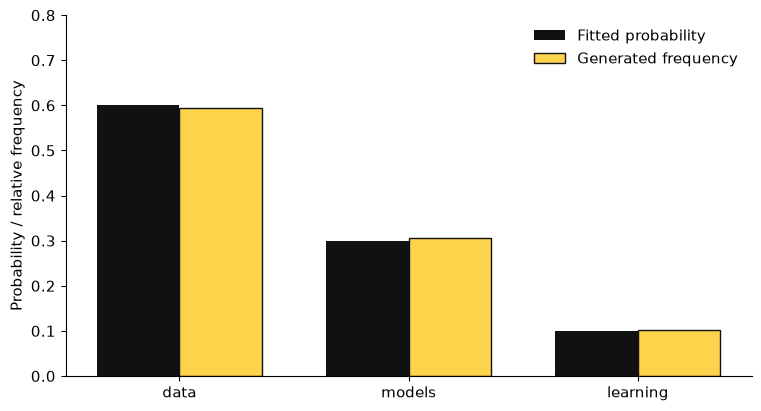

In [8]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (7.5, 4), "font.size": 11})
rng_check = np.random.default_rng(21)
large_sample = rng_check.choice(len(words), size=10_000, p=p_mle)
frequencies = np.bincount(large_sample, minlength=len(words)) / len(large_sample)
mc_se = np.sqrt(p_mle * (1 - p_mle) / len(large_sample))

print("Target:", p_mle)
print("Simulated frequencies:", np.round(frequencies, 4))
print("Marginal Monte Carlo SEs:", np.round(mc_se, 4))

x = np.arange(len(words))
fig, ax = plt.subplots(layout="constrained")
ax.bar(x - 0.18, p_mle, width=0.36, color="#111111", label="Fitted probability")
ax.bar(x + 0.18, frequencies, width=0.36, color="#FED34C", edgecolor="#111111", label="Generated frequency")
ax.set_xticks(x, words)
ax.set_ylabel("Probability / relative frequency")
ax.set_ylim(0, 0.8)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

`plt.subplots` creates a figure and an axes object. `ax.bar` adds bars; the shifts `-0.18` and `+0.18` place each pair side by side. `np.arange(3)` creates positions `0, 1, 2`. `set_xticks` labels those positions, and `plt.show()` displays the figure.

The Monte Carlo standard errors are conditional on the fitted probability vector and assume independent draws. They do not include uncertainty from estimating that vector. Multinomial category frequencies are also correlated, so these marginal standard errors are not simultaneous uncertainty statements. A seed supports reproducibility; it does not eliminate either kind of uncertainty.

## 1.8 · Temperature changes the distribution used for sampling

Many generation interfaces offer a **temperature** parameter. For finite logits $z_j$ and $T>0$,

$$
q_T(j)=\frac{\exp(z_j/T)}{\sum_k\exp(z_k/T)}.
$$

If $z_j=\log p_j$ with all $p_j>0$, then $q_T(j)\propto p_j^{1/T}$. At $T=1$ we recover $p$. Smaller $T$ concentrates mass on the largest probabilities. As $T\to\infty$, the distribution approaches uniformity over this finite support. As $T\downarrow0$, mass concentrates on maximizers; ties require care. Greedy decoding chooses a maximizer directly and is a distinct algorithm.

In [9]:
def temperature_distribution(probabilities, temperature=1.0):
    if temperature <= 0:
        raise ValueError("Temperature must be positive.")
    if np.any(probabilities <= 0):
        raise ValueError("This example requires positive probabilities.")
    scaled_logits = np.log(probabilities) / temperature
    weights = np.exp(scaled_logits - scaled_logits.max())
    return weights / weights.sum()

temperatures = [0.5, 1.0, 2.0]
for temperature in temperatures:
    q = temperature_distribution(p_mle, temperature)
    entropy = -np.sum(q * np.log(q))
    print(f"T={temperature:.1f}: probabilities={np.round(q, 3)}, entropy={entropy:.3f}")

assert np.allclose(temperature_distribution(p_mle, 1.0), p_mle)

T=0.5: probabilities=[0.783 0.196 0.022], entropy=0.594
T=1.0: probabilities=[0.6 0.3 0.1], entropy=0.898
T=2.0: probabilities=[0.473 0.334 0.193], entropy=1.038


`raise ValueError(...)` reports an invalid input. The default argument `temperature=1.0` means the caller may omit it. Subtracting the largest scaled logit before exponentiating leaves the normalized probabilities unchanged and helps prevent overflow. `np.allclose` checks every element with a tolerance.

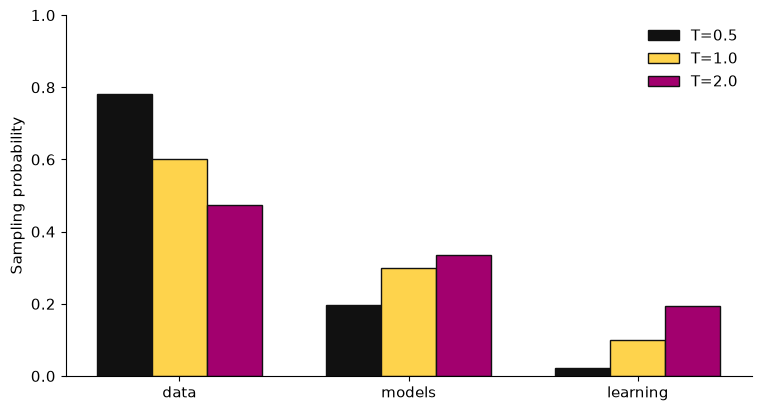

In [10]:
fig, ax = plt.subplots(layout="constrained")
colors = ["#111111", "#FED34C", "#A2006E"]
for index, temperature in enumerate(temperatures):
    q = temperature_distribution(p_mle, temperature)
    ax.bar(x + (index - 1) * 0.24, q, width=0.24,
           color=colors[index], edgecolor="#111111", label=f"T={temperature}")
ax.set_xticks(x, words)
ax.set_ylabel("Sampling probability")
ax.set_ylim(0, 1)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

`enumerate` supplies both a loop counter and the current value. The counter chooses a color and a horizontal offset. The pink bars highlight the flatter distribution at $T=2$.

Temperature changes the generated distribution without changing the trained parameters. Increased diversity is not the same as improved predictive accuracy, uncertainty calibration, or factuality. If a model is confidently wrong, making its output less random can make it consistently wrong.

## 1.9 · From independent tokens to a language model

Independent token sampling discards order. For a sequence $x_1,\ldots,x_T$, the probability chain rule gives

$$
p_\theta(x_{1:T})=\prod_{t=1}^{T}p_\theta(x_t\mid x_{<t}).
$$

The chain rule is an identity; it does not assume a Markov process. A **bigram model** adds the approximation

$$
p_\theta(x_t\mid x_{<t})=p_\theta(x_t\mid x_{t-1}).
$$

The previous token is the entire context. This is an explicit first-order Markov assumption. A transformer later replaces this small conditioning rule with a learned function of a longer context. The basic next-token probability and sequential sampling interpretation remain useful.

We add special symbols: `<bos>` marks the beginning, and `<eos>` marks the end. For “data support models,” our scored prediction events are

$$
\texttt{<bos>}\to\texttt{data},\quad
\texttt{data}\to\texttt{support},\quad
\texttt{support}\to\texttt{models},\quad
\texttt{models}\to\texttt{<eos>}.
$$

The start symbol is a context, not an output token. Including the end symbol makes stopping part of the probability model. In our smoothed finite-state example every context gives positive probability to `<eos>`, so the process eventually stops with probability one. We will still impose a length cap in software.

### Make a small, transparent corpus

In [11]:
train_sentences = [
    "data support models",
    "models explain data",
    "data guide learning",
    "learning improves models",
    "models generate data",
    "data support learning",
]
test_sentences = [
    "models support learning",
    "data explain models",
    "learning generate data",
]

def tokenize(sentence):
    return sentence.lower().split()

print(tokenize(train_sentences[0]))

['data', 'support', 'models']


This corpus was written for the lesson, not sampled from a population of natural language. Awkward test sentences are intentional combinations for inspecting the model, not a benchmark of linguistic quality. We split by complete sentences before counting transitions so adjacent tokens from the same sentence do not leak across partitions.

`sentence.lower()` lowercases a string, and `.split()` separates it at whitespace. Real tokenizers handle punctuation, subwords, and many other cases; our authored sentences avoid punctuation. Changing a tokenizer changes the modeled outcome space.

### Build a vocabulary and lookup tables

In [12]:
training_words = []
for sentence in train_sentences:
    training_words.extend(tokenize(sentence))

lexical_vocabulary = sorted(set(training_words))
output_vocabulary = lexical_vocabulary + ["<eos>"]
contexts = ["<bos>"] + lexical_vocabulary

word_to_id = {word: index for index, word in enumerate(output_vocabulary)}
context_to_id = {word: index for index, word in enumerate(contexts)}

print("Output vocabulary:", output_vocabulary)
print("Index of 'data':", word_to_id["data"])
print("Number of output categories:", len(output_vocabulary))

Output vocabulary: ['data', 'explain', 'generate', 'guide', 'improves', 'learning', 'models', 'support', '<eos>']
Index of 'data': 0
Number of output categories: 9


`extend` adds each item from a list to another list. `set` removes duplicates; `sorted` places them in a deterministic order. `+` concatenates Python lists. A **dictionary** maps keys to values: `word_to_id["data"]` retrieves the integer ID associated with a string. The expression `{word: index for ...}` is a dictionary comprehension, analogous to the list comprehension used earlier.

Only training data determine the vocabulary. The hand-written test set uses words already present in training. A real application needs a specified strategy for unseen words, such as a training-defined `<unk>` symbol or a fixed subword tokenizer. Do not expand the vocabulary using the final test data merely to make evaluation convenient.

### Count transitions and estimate conditional distributions

In [13]:
transition_counts = np.zeros((len(contexts), len(output_vocabulary)), dtype=int)

for sentence in train_sentences:
    sequence = ["<bos>"] + tokenize(sentence) + ["<eos>"]
    for previous, following in zip(sequence[:-1], sequence[1:]):
        row = context_to_id[previous]
        column = word_to_id[following]
        transition_counts[row, column] += 1

alpha = 0.5
row_totals = transition_counts.sum(axis=1, keepdims=True)
transition_probabilities = (transition_counts + alpha) / (
    row_totals + alpha * len(output_vocabulary)
)

assert np.allclose(transition_probabilities.sum(axis=1), 1.0)
print("Transition count matrix shape:", transition_counts.shape)
print("Number of training prediction events:", transition_counts.sum())

Transition count matrix shape: (9, 9)
Number of training prediction events: 24


`np.zeros((r, c), dtype=int)` creates an integer matrix with $r$ rows and $c$ columns. `sequence[:-1]` omits the last item; `sequence[1:]` omits the first. Zipping the two produces consecutive pairs. `transition_counts[row, column] += 1` increments the selected entry.

`axis=1` sums across columns, producing one total per context. `keepdims=True` retains a column-shaped result, so each matrix row is divided by its own normalizing constant through broadcasting. Without tracking these shapes, a calculation can fail or normalize along the wrong dimension.

Statistically, the model is a separate categorical distribution for each context. Its likelihood groups transition counts by row. Adding $\alpha$ yields row-wise posterior predictive probabilities under independent symmetric Dirichlet priors. This is a small conditional density estimator, not a neural network.

P(    data | data) = 0.053
P( explain | data) = 0.053
P(generate | data) = 0.053
P(   guide | data) = 0.158
P(improves | data) = 0.053
P(learning | data) = 0.053
P(  models | data) = 0.053
P( support | data) = 0.263
P(   <eos> | data) = 0.263


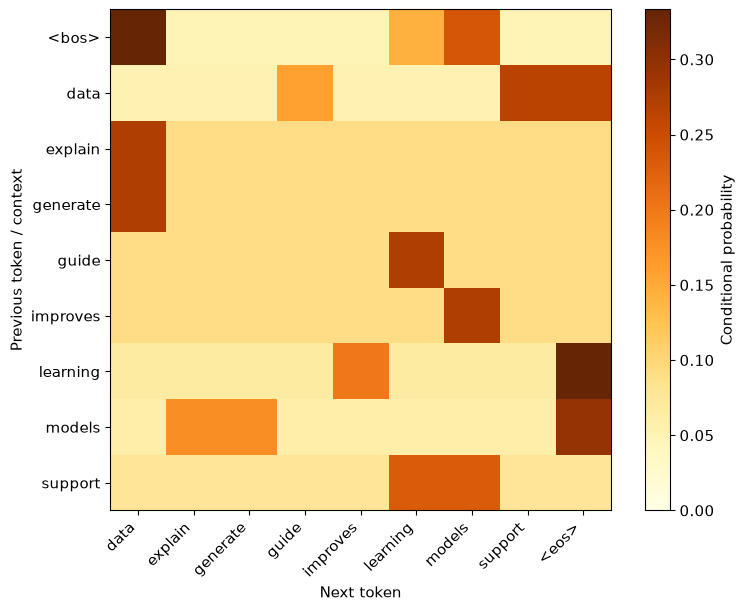

In [14]:
data_row = context_to_id["data"]
for token, probability in zip(output_vocabulary, transition_probabilities[data_row]):
    print(f"P({token:>8} | data) = {probability:.3f}")

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
image = ax.imshow(transition_probabilities, cmap="YlOrBr", vmin=0,
                  vmax=transition_probabilities.max())
ax.set_xticks(np.arange(len(output_vocabulary)), output_vocabulary, rotation=45, ha="right")
ax.set_yticks(np.arange(len(contexts)), contexts)
ax.set_xlabel("Next token")
ax.set_ylabel("Previous token / context")
fig.colorbar(image, ax=ax, label="Conditional probability")
plt.show()

The format `:>8` right-aligns a token in a field of width eight. `imshow` displays a matrix as an image; the colorbar translates shading back to probabilities. The rows sum to one; columns generally do not. A heatmap is useful only if you know which axis represents the conditioning event.

## 1.10 · Generate a sequence one decision at a time

In [15]:
def generate_sentence(probability_table, rng, max_tokens=15):
    previous = "<bos>"
    result = []
    for step in range(max_tokens):
        row = context_to_id[previous]
        next_id = rng.choice(len(output_vocabulary), p=probability_table[row])
        next_word = output_vocabulary[next_id]
        if next_word == "<eos>":
            return " ".join(result), "eos"
        result.append(next_word)
        previous = next_word
    return " ".join(result), "length cap"

rng_text = np.random.default_rng(8670)
for repetition in range(5):
    sentence, stop_reason = generate_sentence(transition_probabilities, rng_text)
    print(f"{repetition + 1}. {sentence!r} [{stop_reason}]")

1. 'data' [eos]
2. '' [eos]
3. 'data guide learning support improves generate support support' [eos]
4. 'learning data generate generate' [eos]
5. 'learning' [eos]


`range(15)` produces integers zero through fourteen. The loop samples one next token per iteration, appends it to a list, and updates the context. `append` adds a single item. `return` can return a tuple; the caller unpacks it into `sentence` and `stop_reason`. `!r` displays a string with quotes, making an empty generated sentence visible.

The length cap is an operational stopping rule, not an additional learned token. A sequence stopped by the cap has been truncated; it is not the same event as a model-generated `<eos>`. The printed stop reason prevents that distinction from being hidden.

These outputs may repeat, stop immediately, or be ungrammatical. Additive smoothing allows every next token from every context, and a one-token context cannot represent long-range syntax. That is an observation about our fitted model. The random generator is doing the sampling job we asked it to do.

This code repeatedly samples from a **fixed table** of smoothed probabilities. It does not integrate a shared uncertain transition matrix over the entire generated path. A fully Bayesian sequence posterior predictive would account for dependence induced by that shared parameter uncertainty. The plug-in sampler is sufficient for understanding the first algorithm, provided we name what it computes.

## 1.11 · Evaluate prediction separately from generation

We evaluate probabilities assigned to observed test tokens, using their actual preceding tokens as contexts. We do not condition on the model's previously sampled tokens during this calculation. In neural language modeling, training on the observed prefix is commonly called **teacher forcing**.

In [16]:
def bigram_log_loss(sentences, probability_table):
    losses = []
    for sentence in sentences:
        sequence = ["<bos>"] + tokenize(sentence) + ["<eos>"]
        for previous, following in zip(sequence[:-1], sequence[1:]):
            row = context_to_id[previous]
            column = word_to_id[following]
            losses.append(-np.log(probability_table[row, column]))
    return float(np.mean(losses))

unigram_counts = transition_counts.sum(axis=0)
unigram_probabilities = (unigram_counts + alpha) / (
    unigram_counts.sum() + alpha * len(output_vocabulary)
)
unigram_table = np.tile(unigram_probabilities, (len(contexts), 1))

evaluation = {}
for label, table in [("Unigram", unigram_table), ("Bigram", transition_probabilities)]:
    train_loss = bigram_log_loss(train_sentences, table)
    test_loss = bigram_log_loss(test_sentences, table)
    evaluation[label] = (train_loss, test_loss)
    print(f"{label}: train={train_loss:.3f}, test={test_loss:.3f}, test perplexity={np.exp(test_loss):.3f}")

Unigram: train=1.976, test=1.994, test perplexity=7.348
Bigram: train=1.381, test=1.816, test perplexity=6.144


`axis=0` sums down the context rows, leaving a count for each output token. `np.tile` repeats the same unigram vector in every row; this constructs a baseline that ignores the context while using the same scoring function and vocabulary. Both models include `<eos>` in their prediction events and use the same fixed smoothing parameter.

The dictionary `evaluation` stores a pair of results for each model. The function pools all prediction events before averaging: longer sentences contribute more terms. An equal-weight average of sentence-level average losses would be a different estimand. Decide which target you want before comparing models.

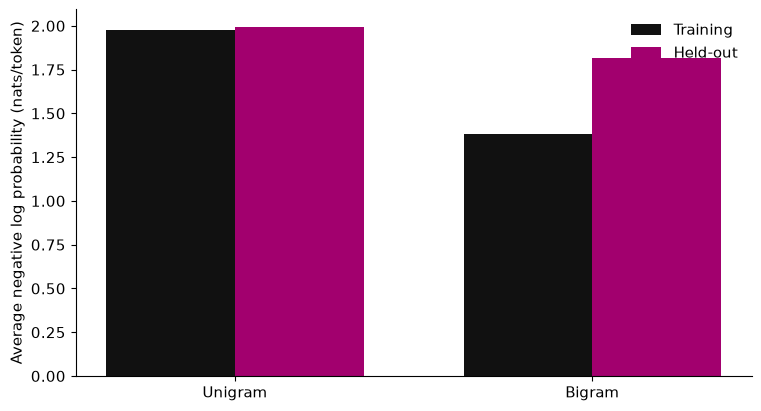

In [17]:
fig, ax = plt.subplots(layout="constrained")
positions = np.arange(2)
train_losses = [evaluation[name][0] for name in ["Unigram", "Bigram"]]
test_losses = [evaluation[name][1] for name in ["Unigram", "Bigram"]]
ax.bar(positions - 0.18, train_losses, width=0.36, color="#111111", label="Training")
ax.bar(positions + 0.18, test_losses, width=0.36, color="#A2006E", label="Held-out")
ax.set_xticks(positions, ["Unigram", "Bigram"])
ax.set_ylabel("Average negative log probability (nats/token)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Compare the outputs before drawing a conclusion. A conditional model can improve training fit while generalizing poorly to different transition patterns. The toy corpus is much too small and deliberately constructed to support a scientific claim of superiority. The purpose is to make the distinction between training fit and held-out prediction observable.

For a real study, define the target population, reserve a test set, choose smoothing on a separate validation set, and compare systems on the same test documents. Tokens within a document are dependent. Treating thousands of token losses as independent observations can give misleadingly narrow intervals. Resampling documents or another justified independent cluster is often more defensible; the number of independent clusters still matters.

### Predictive probability is not factual confidence

Our model learns which tokens follow others in the corpus. It has no variable representing whether “models explain data” is scientifically correct in a particular context. A larger model's next-token objective also does not itself supply a calibrated probability that an entire answer is true. Evaluating factuality requires a defined factual target, evidence, and an appropriate measurement procedure. Later chapters develop retrieval and evaluation in response to this gap.

## 1.12 · Common Python problems and how to diagnose them

| Symptom | Likely cause | First action |
|:--|:--|:--|
| `NameError: name 'np' is not defined` | The import cell has not run in this kernel. | Restart and run all cells in order. |
| `ModuleNotFoundError` | The selected kernel does not have the package. | Confirm the notebook uses the course environment. |
| `IndexError` | A position is outside the array/list. | Print its length or shape and inspect the index. |
| `KeyError` for a token | The token is absent from the dictionary. | Inspect the vocabulary and tokenization; specify unknown-token handling. |
| `IndentationError` | A loop/function body is not consistently indented. | Use four spaces and check the enclosing block. |
| Probabilities do not sum to one | The wrong axis or denominator was used. | Print row totals and check `axis` and `keepdims`. |
| Different output after rerunning only one cell | A generator's internal state has advanced. | Recreate the seeded generator or restart and run all. |

Do not fix `log(0)` by silently clipping probabilities and then reporting the score as if it came from the original model. If you change the probabilities, document the changed model and normalization. Likewise, rounding is for display; premature rounding can destroy a probability sum or a numerical comparison.

## 1.13 · Separate estimation error from Monte Carlo error

Generating more observations from a fitted model estimates that model more precisely; it does not automatically move it closer to the data-generating distribution. We can separate these errors because the true categorical distribution is known in this experiment.

For a numerical summary $g$, define $\mu_0=\mathbb E_{P_0}g(X)$, $\mu_{\widehat\theta}=\mathbb E_{P_{\widehat\theta}}g(X)$, and the average of $M$ conditionally independent generated draws, $\widehat\mu_M=M^{-1}\sum_{m=1}^M g(\widetilde X_m)$. Then

$$
\widehat\mu_M-\mu_0
=\underbrace{\widehat\mu_M-\mu_{\widehat\theta}}_{\text{Monte Carlo error}}
+\underbrace{\mu_{\widehat\theta}-\mu_0}_{\text{fitting and model error}},
$$

$$
\operatorname{Var}(\widehat\mu_M\mid D)
=\frac{\operatorname{Var}_{P_{\widehat\theta}}\{g(X)\}}{M}.
$$

The variance identity assumes a finite second moment and independent draws conditional on the fitted model. For a category frequency, take $g(x)=\mathbf1\{x=j\}$. Increasing `size` in a sampling call reduces the first error term; collecting better training data or improving the model addresses the second. This is the mathematical reason for the separate simulation and evaluation lanes in the framework.

For each training size, fit a smoothed probability vector and calculate its exact KL divergence from the true vector. The repeated fits represent sampling variation in estimation. A separate large generated sample then approximates one fitted vector, not the unknown truth.

20 mean KL: 0.038 90% simulation range: [0.001  0.1058]
100 mean KL: 0.0096 90% simulation range: [0.0003 0.0273]
500 mean KL: 0.0018 90% simulation range: [0.0001 0.0053]


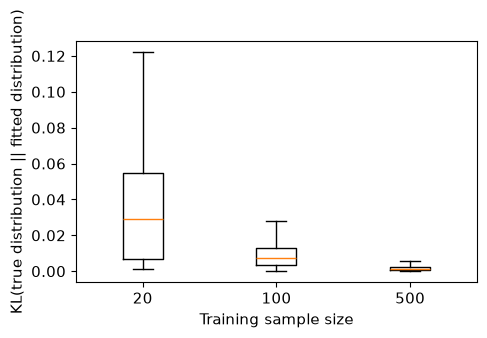

True distribution: [0.6 0.3 0.1]
One small-data fit: [0.478 0.348 0.174]
Large generated sample frequencies: [0.478 0.349 0.173]


In [18]:
curve_rng = np.random.default_rng(20261)
true_vector = np.array([0.6, 0.3, 0.1])
training_sizes = [20, 100, 500]
kl_by_size = []
for size in training_sizes:
    repeated_counts = curve_rng.multinomial(size, true_vector, size=300)
    estimates = (repeated_counts + 1) / (size + len(true_vector))
    divergence = np.sum(true_vector * np.log(true_vector / estimates), axis=1)
    kl_by_size.append(divergence)
    print(size, 'mean KL:', round(divergence.mean(), 4),
          '90% simulation range:', np.quantile(divergence, [0.05, 0.95]).round(4))
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.boxplot(kl_by_size, tick_labels=training_sizes, showfliers=False)
ax.set(xlabel='Training sample size', ylabel='KL(true distribution || fitted distribution)')
plt.tight_layout()
plt.show()

small_fit = (curve_rng.multinomial(20, true_vector) + 1) / 23
large_generated = curve_rng.multinomial(100000, small_fit) / 100000
print('True distribution:', true_vector)
print('One small-data fit:', small_fit.round(3))
print('Large generated sample frequencies:', large_generated.round(3))

The simulation ranges summarize variation across 300 independently generated training datasets; they are not confidence intervals for one fitted model. The large generated sample should be close to `small_fit`, even when that fit differs from the truth. This is why a convincing-looking collection of model samples cannot replace evaluation on independent real observations.

## 1.14 · Exercises

Attempt the questions before reading the worked solutions. You can use the same notebook; keep experimental changes in separate cells so the main example remains reproducible.

### Exercise 1 · Read a small Python calculation

For `a = np.array([2, 5, 3])`, predict the values and shapes of `a[1]`, `a[:2]`, `a / a.sum()`, and `a * 2`. Explain how `[2, 5, 3] * 2` differs.

### Exercise 2 · Estimate, smooth, and interpret

For counts $(8,2,0)$, derive the categorical MLE and the smoothed estimator with $\alpha=1$. Compute the log loss if the next observation is category three. Is the smoothed estimate a posterior mean, posterior mode, or both under a Dirichlet$(1,1,1)$ prior?

### Exercise 3 · Separate sampling error from estimation error

Generate 100, 1,000, and 10,000 observations from the fixed vector $(0.6,0.3,0.1)$. Compare the first-category frequency with its target. Explain why a single run need not become closer at every sample size. What experiment would be required to include uncertainty in the original fitted vector?

### Exercise 4 · Understand temperature mathematically

Show that for two positive base probabilities,

$$
\frac{q_T(i)}{q_T(j)}=\left(\frac{p_i}{p_j}\right)^{1/T}.
$$

Compute the ratio when $p_i=0.6$, $p_j=0.3$, and $T\in\{0.5,1,2\}$. What happens if the base probabilities are tied? Does the ratio tell you whether either token is true?

### Exercise 5 · Audit one transition row

Using the training corpus, count the transitions following `data` by hand, including end-of-sentence transitions. With $\alpha=0.5$, compute the probabilities of `support`, `<eos>`, and `generate` given `data`. Check them against the matrix.

### Exercise 6 · Score a whole sentence

For “data support models,” write its probability as a product of four terms including `<eos>`. Implement the log probability as a sum. Explain why averaging over four events differs from averaging only over the three lexical words.

### Exercise 7 · Design an honest comparison

You try twenty smoothing parameters and report the one with the lowest score on `test_sentences`. Identify the problem, propose a training/validation/test procedure, and state an appropriate resampling unit if sentences are grouped within documents.

### Exercise 8 · A small extension with a baseline

Create twelve new, original sentences using a small vocabulary. Reserve complete sentences for validation and testing before fitting. Compare unigram and bigram models with the same tokenizer, support, and scoring convention. Report a failure example and one limitation. Do not interpret the small exercise as a reliable estimate of general language performance.

## 1.15 · Worked solutions

### Solution 1

The scalar `a[1]` is `5`; `a[:2]` is an array `[2, 5]` with shape `(2,)`; normalization gives `[0.2, 0.5, 0.3]` with shape `(3,)`; and array multiplication gives `[4, 10, 6]`. Python list multiplication repeats items, producing `[2, 5, 3, 2, 5, 3]`.

### Solution 2

The MLE is $(0.8,0.2,0)$; smoothing gives $(9/13,3/13,1/13)$. The loss on category three changes from infinity to $\log 13\approx2.565$ nats. The smoothed estimate is the posterior mean and one-step predictive vector. The posterior is Dirichlet$(9,3,1)$; its mode lies on the boundary, so it does not equal that mean.

In [19]:
exercise_counts = np.array([8, 2, 0])
exercise_prediction = (exercise_counts + 1) / (exercise_counts.sum() + 3)
print("Smoothed estimate:", exercise_prediction)
print("Loss on third category:", -np.log(exercise_prediction[2]))

Smoothed estimate: [0.69230769 0.23076923 0.07692308]
Loss on third category: 2.5649493574615367


### Solution 3

In [20]:
rng_exercise = np.random.default_rng(7)
for n in [100, 1_000, 10_000]:
    draw = rng_exercise.choice(3, size=n, p=np.array([0.6, 0.3, 0.1]))
    first_frequency = np.mean(draw == 0)
    expected_se = np.sqrt(0.6 * 0.4 / n)
    print(f"n={n:5d}, frequency={first_frequency:.4f}, MC SE={expected_se:.4f}")

n=  100, frequency=0.6300, MC SE=0.0490
n= 1000, frequency=0.6060, MC SE=0.0155
n=10000, frequency=0.5921, MC SE=0.0049


`draw == 0` is a Boolean array; its mean is the proportion of `True` entries. The standard error decreases at rate $n^{-1/2}$, but realized deviations need not decrease monotonically. To include fitting uncertainty, repeatedly generate or resample training datasets under justified assumptions, refit the model, and then study predictions or generated summaries. A nested simulation can separate variability from fitting and from generation.

### Solution 4

The normalization cancels in the ratio. The three ratios are $4$, $2$, and $\sqrt2$. Tied positive base probabilities remain tied at every positive temperature. These are probability ratios for modeled outcomes, with no independent statement about truth.

### Solution 5

`data` has five outgoing events: `support` twice, `guide` once, and `<eos>` twice. There are nine output categories. The normalizer is $5+9(0.5)=9.5$. Therefore the requested probabilities are $2.5/9.5$, $2.5/9.5$, and $0.5/9.5$.

In [21]:
row = context_to_id["data"]
for token, expected in [("support", 2.5 / 9.5), ("<eos>", 2.5 / 9.5), ("generate", 0.5 / 9.5)]:
    actual = transition_probabilities[row, word_to_id[token]]
    assert np.isclose(actual, expected)
    print(token, round(float(actual), 4))

support 0.2632
<eos> 0.2632
generate 0.0526


### Solution 6

The product is $p(\texttt{data}\mid\texttt{<bos>})p(\texttt{support}\mid\texttt{data})p(\texttt{models}\mid\texttt{support})p(\texttt{<eos>}\mid\texttt{models})$. Its logarithm is the sum of the corresponding four log probabilities.

In [22]:
sentence_events = [("<bos>", "data"), ("data", "support"),
                   ("support", "models"), ("models", "<eos>")]
log_probability = 0.0
for previous, following in sentence_events:
    log_probability += np.log(transition_probabilities[context_to_id[previous], word_to_id[following]])
print("Sentence log probability:", round(float(log_probability), 4))
print("Sentence probability:", round(float(np.exp(log_probability)), 6))
assert np.isclose(-log_probability / 4, bigram_log_loss(["data support models"], transition_probabilities))

Sentence log probability: -5.1237
Sentence probability: 0.005954


Leaving out `<eos>` scores the lexical prefix without scoring the decision to stop. The set of prediction events and denominator both change. Neither convention should be switched between competing systems without explanation.

### Solution 7

The test set has become a tuning set. Split at the independent unit first; fit transition counts and vocabulary on training data; choose smoothing on validation data; then report the selected procedure's performance once on an untouched test set. If refitting on combined training and validation data, specify that step in advance. Resample independent documents rather than individual token losses when document-level dependence is the relevant structure. With few documents, uncertainty estimates remain unstable.

### Solution 8 · Reporting checklist

Record the corpus, tokenizer, split, vocabulary/unknown-token rule, smoothing choices, and score definition. Show both models' losses on the same test events and several generated outputs, including failures and stop reasons. State whether the apparent gain could be due to chance, repeated tuning, or an unusually favorable split. A negative or inconclusive result is a valid result.

## 1.16 · What this chapter gives us

We have built a complete small modeling workflow: encode outcomes, fit probabilities, score held-out observations, sample new outcomes, and inspect the assumptions. The bigram table makes context-dependent prediction explicit. It also exposes the cost of a restricted context and sparse counts.

The next chapter replaces hand-estimated probability tables with differentiable functions. You will learn tensors and automatic differentiation through regression and a small neural predictor before using those tools for attention. Keep the same questions: what is the modeled distribution, what is optimized, and what evidence supports the result?

### Further reading

- [Python Tutorial](https://docs.python.org/3/tutorial/): basic values, lists, control flow, and functions.
- [NumPy: the absolute basics for beginners](https://numpy.org/doc/stable/user/absolute_beginners.html): arrays, indexing, shapes, and numerical operations.
- [Speech and Language Processing, author-hosted draft](https://web.stanford.edu/~jurafsky/slp3/): the chapter on n-gram language models develops count-based sequence modeling further.

All data in this chapter are small, original teaching examples. Their role is to make a calculation inspectable, not to establish empirical claims about modern LLMs.